In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import psycopg2
from sqlalchemy import create_engine
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, MinMaxScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, accuracy_score

In [ ]:
df = pd.read_csv("train.csv")
print(f"set_shape:{df.shape}")
num_cols = df.select_dtypes(include=np.number).columns.tolist()[2:7]
cat_cols = df.select_dtypes("object").columns.tolist()
num_cols
df

set_shape:(891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
...,...,...,...,...,...,...,...,...,...,...,...,...
886,887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.0000,NaN,S
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.0000,B42,S
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.4500,NaN,S
889,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.0000,C148,C


In [ ]:
df["Survived"].describe()
pd.DataFrame([df["Survived"].value_counts()])
df.isnull().sum()
df["Age"].describe()
df.duplicated().sum()
imputer = SimpleImputer(strategy="mean")
imputer.fit(df[num_cols])
df[num_cols] = imputer.transform(df[num_cols])
df[num_cols].describe()
df["FamilySize"] = df["SibSp"] + df["Parch"] + 1
def is_a(FamilySize):
    if FamilySize == 1:
        return 1
    else:
        return 0
    
df["IsAlone"] = df["FamilySize"].apply(is_a)
df["FamilySize"].describe()
df["Name"] = df["Name"].str.replace(", ", ",")
def split_title(Name):
    return Name.split(",")[1]
df["ExtractTitle"] = df["Name"].apply(split_title)


C:\Users\USER\AppData\Local\Temp\ipykernel_7544\118311333.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=df, x="ExtractT", y="Survived", palette="Set2", inner="stick" ,bw=0.2)
C:\Users\USER\AppData\Local\Temp\ipykernel_7544\118311333.py:8: FutureWarning: 

The `bw` parameter is deprecated in favor of `bw_method`/`bw_adjust`.
Setting `bw_method=0.2`, but please see docs for the new parameters
and update your code. This will become an error in seaborn v0.15.0.

  sns.violinplot(data=df, x="ExtractT", y="Survived", palette="Set2", inner="stick" ,bw=0.2)


<Axes: xlabel='ExtractT', ylabel='Survived'>

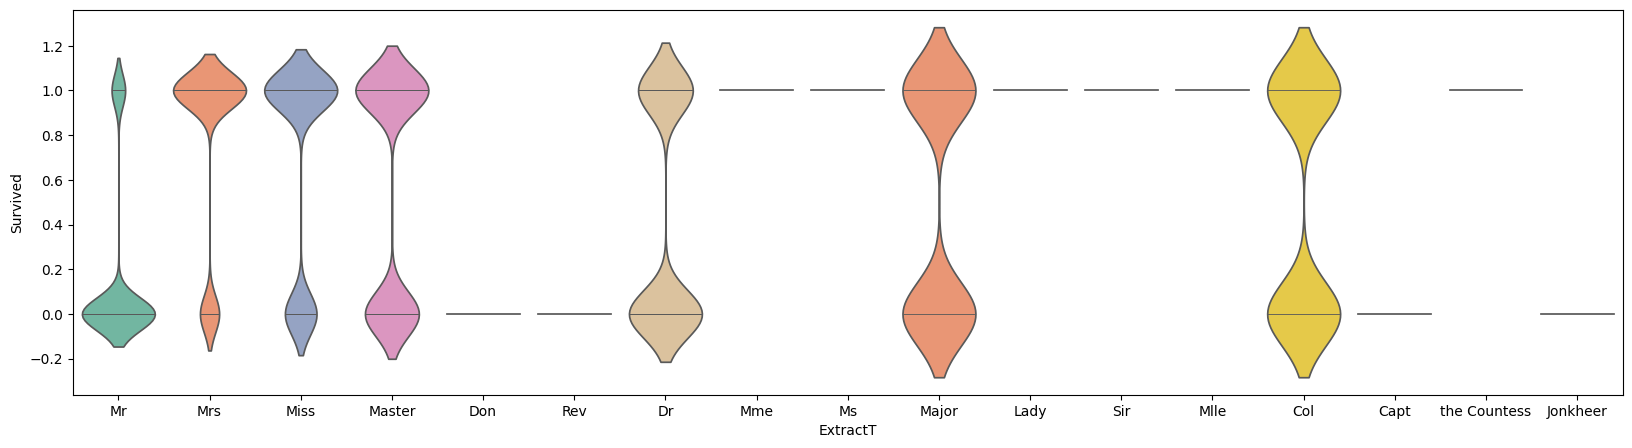

In [ ]:
def first_w(ExtractTitle):
    return ExtractTitle.split(". ")[0]
df["ExtractT"] = df["ExtractTitle"].apply(first_w)
tile_s = df[df["Survived"] == 1].groupby("ExtractT").agg(survived=("Survived", "count")).reset_index()
tile_d_s = df[df["Survived"] == 0].groupby("ExtractT").agg(did_not_survived=("Survived", "count")).reset_index()
df.drop(columns="ExtractTitle", inplace=True)
plt.figure(figsize=(20, 5))
sns.violinplot(data=df, x="ExtractT", y="Survived", palette="Set2", inner="stick" ,bw=0.2)

In [ ]:
tile_survived = tile_s.merge(tile_d_s, on="ExtractT", how="outer")
tile_survived

,ExtractT,survived,did_not_survived
0,Capt,NaN,1.0
1,Col,1.0,1.0
2,Don,NaN,1.0
3,Dr,3.0,4.0
4,Jonkheer,NaN,1.0
5,Lady,1.0,NaN
6,Major,1.0,1.0
7,Master,23.0,17.0
8,Miss,127.0,55.0
9,Mlle,2.0,NaN


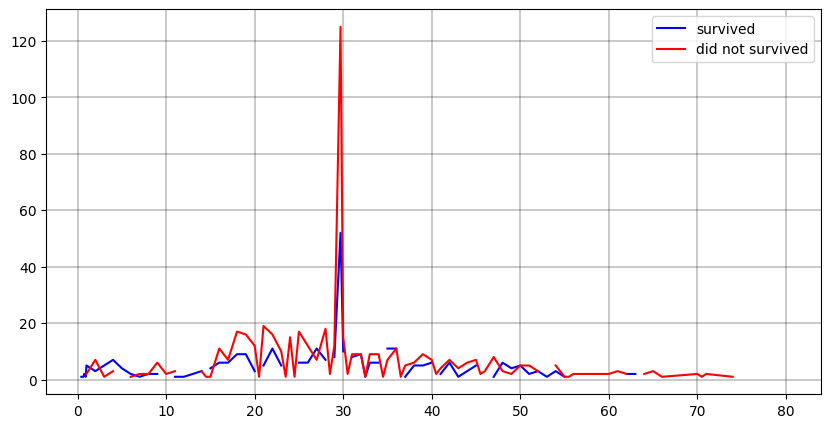

In [ ]:
age_c_s = df[df["Survived"] == 1].groupby("Age").agg(count_survivals=("Age", "count")).reset_index()
age_c_n = df[df["Survived"] == 0].groupby("Age").agg(count_not_survivals=("Age", "count")).reset_index()
age_count_df = age_c_s.merge(age_c_n, on="Age", how="outer").sort_values("Age", ascending=True)
plt.figure(figsize=(10, 5))
plt.plot(age_count_df["Age"], age_count_df["count_survivals"], color="blue")
plt.plot(age_count_df["Age"], age_count_df["count_not_survivals"], color="red")
plt.grid(linewidth=0.3, color="black")
plt.legend(["survived", "did not survived"])

C:\Users\USER\AppData\Local\Temp\ipykernel_7544\62491132.py:2: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.lineplot(data=age_c, x="Age", y="count", palette="Set2")


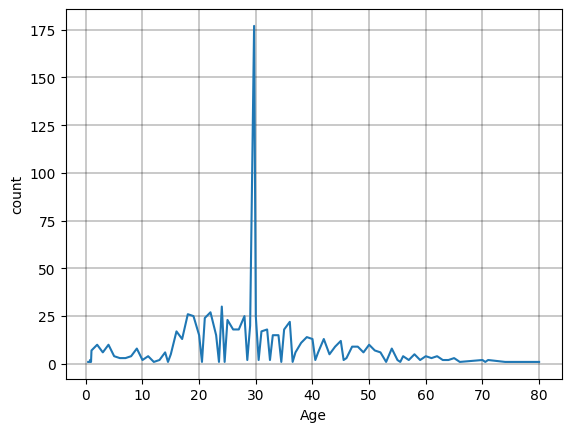

In [ ]:
age_c = df.groupby("Age").agg(count=("Age", "count"))
sns.lineplot(data=age_c, x="Age", y="count", palette="Set2")
plt.grid(linewidth=0.3, color="black")

C:\Users\USER\AppData\Local\Temp\ipykernel_7544\2522318589.py:1: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.histplot(data=df, x="Fare", palette="Set2")


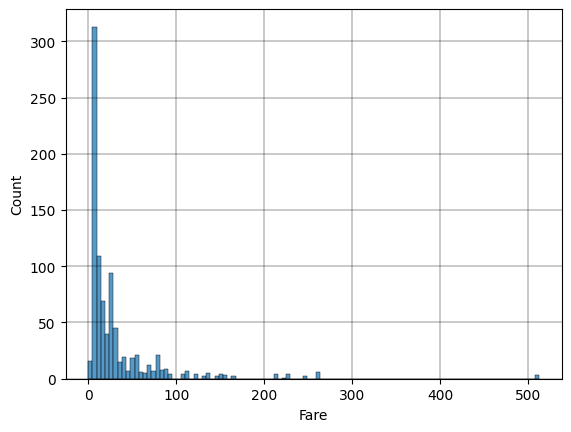

In [ ]:
sns.histplot(data=df, x="Fare", palette="Set2")
plt.grid(linewidth=0.3, color="black")

C:\Users\USER\AppData\Local\Temp\ipykernel_7544\650798420.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=df, y="Pclass", palette="Set2", bw=0.3)
C:\Users\USER\AppData\Local\Temp\ipykernel_7544\650798420.py:1: FutureWarning: 

The `bw` parameter is deprecated in favor of `bw_method`/`bw_adjust`.
Setting `bw_method=0.3`, but please see docs for the new parameters
and update your code. This will become an error in seaborn v0.15.0.

  sns.violinplot(data=df, y="Pclass", palette="Set2", bw=0.3)


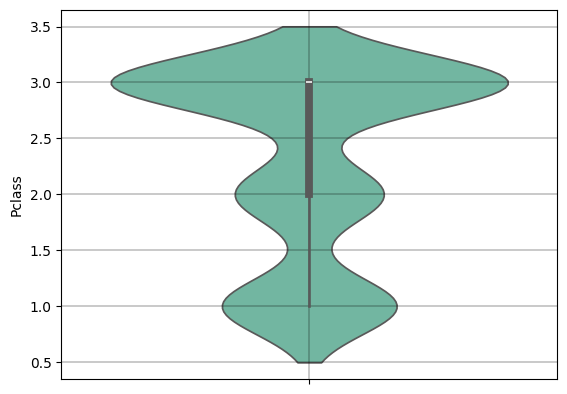

In [ ]:
sns.violinplot(data=df, y="Pclass", palette="Set2", bw=0.3)
plt.grid(linewidth=0.3, color="black")

C:\Users\USER\AppData\Local\Temp\ipykernel_7544\2799417097.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x="Sex", palette="Set2")


<Axes: xlabel='Sex', ylabel='count'>

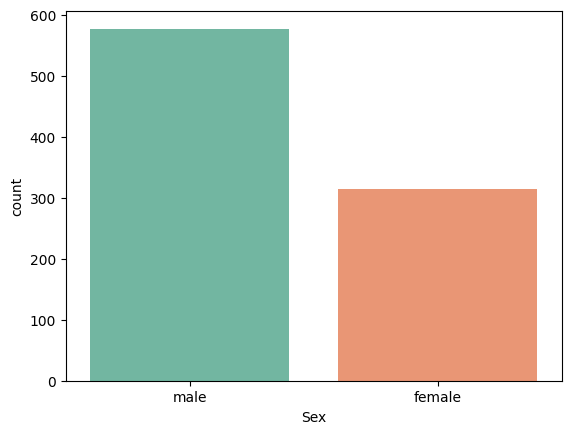

In [ ]:
sns.countplot(data=df, x="Sex", palette="Set2")

<Axes: xlabel='Embarked', ylabel='count'>

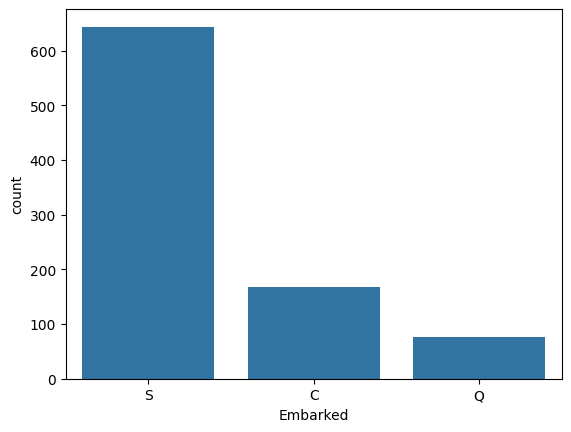

In [ ]:
sns.countplot(data=df, x="Embarked")

<Axes: ylabel='SibSp'>

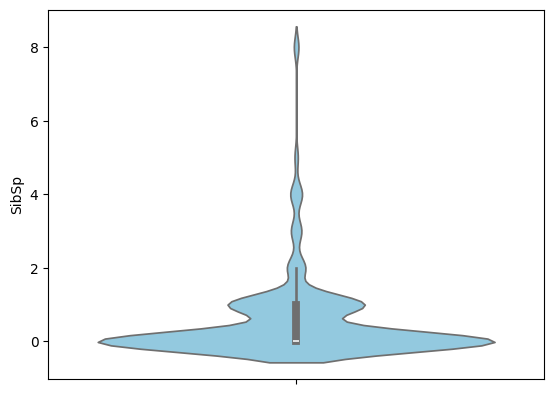

In [ ]:
sns.violinplot(data=df, y="SibSp", color="skyblue")

<Axes: ylabel='Parch'>

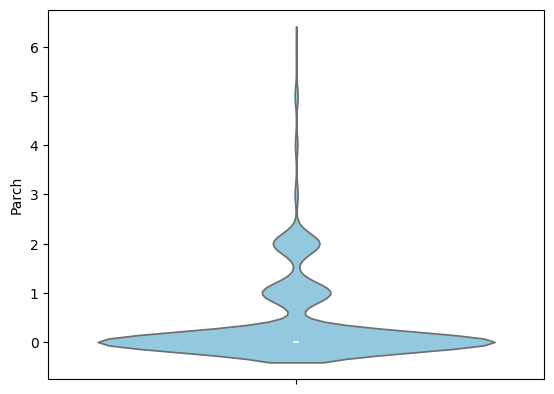

In [ ]:
sns.violinplot(data=df, y="Parch", color="skyblue")

([<matplotlib.patches.Wedge at 0x189063eb6d0>,
 [Text(-0.08717504250598822, 1.096540246395033, 'male_survived'),
  Text(-1.0274001775358852, -0.6200394142304435, 'male_not_survived'),
  Text(-0.4203473266631696, -1.12396980607449, 'female_survived'),
  Text(0.8173144190194539, -0.8786336781975141, 'female_not_survived')],
 [Text(-0.04755002318508448, 0.5981128616700179, '52.5%'),
  Text(-0.5993167702292663, -0.361689658301092, '12.2%'),
  Text(-0.24520260722018222, -0.6556490535434525, '9.1%'),
  Text(0.4767667444280147, -0.5125363122818832, '26.2%')])

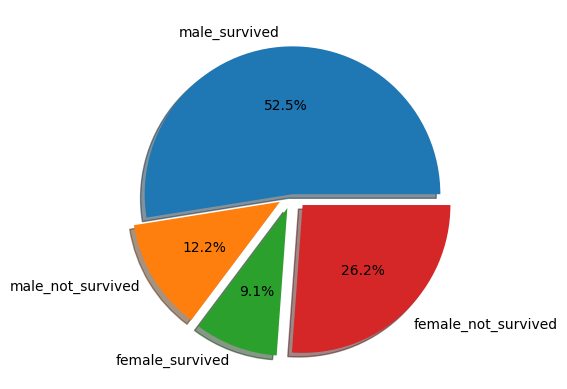

In [ ]:
sur_by_male = df[df["Sex"] == "male"].groupby("Survived").agg(count_male=("Sex", "count"))
sur_by_female = df[df["Sex"] == "female"].groupby("Survived").agg(count_female=("Sex", "count"))
sur_by_sex = sur_by_male.merge(sur_by_female, on="Survived", how="outer").reset_index()
dict = {}
dict["male_survived"] = sur_by_sex["count_male"].iloc[0]
dict["male_not_survived"] = sur_by_sex["count_male"].iloc[1]
dict["female_survived"] = sur_by_sex["count_female"].iloc[0]
dict["female_not_survived"] = sur_by_sex["count_female"].iloc[1]
plt.pie(list(dict.values()), labels=["male_survived", "male_not_survived", "female_survived", "female_not_survived"], shadow=True, explode=[0, 0.1, 0.1, 0.1], autopct="%1.1f%%")

([<matplotlib.patches.Wedge at 0x1890643fca0>,
 [Text(0.9759356905408233, 0.5074933772263501, 'p : 1 survived'),
  Text(0.33031388650647886, 1.049234357224822, 'p : 2 survived'),
  Text(-0.44988920060381654, 1.0037926614495938, 'p : 3 survived'),
  Text(-0.9915459714063702, 0.47627364674921685, 'p : 1 n_survived'),
  Text(-1.0829501045824252, -0.19292244811041137, 'p : 2 n_survived'),
  Text(0.28189055016107806, -1.0632674723369868, 'p : 3 n_survived')],
 [Text(0.5323285584768126, 0.276814569396191, '15.26%'),
  Text(0.18017121082171572, 0.5723096493953573, '9.76%'),
  Text(-0.24539410942026355, 0.5475232698815966, '13.36%'),
  Text(-0.5408432571307473, 0.2597856254995728, '8.98%'),
  Text(-0.5907000570449592, -0.10523042624204255, '10.89%'),
  Text(0.15375848190604258, -0.5799640758201745, '41.75%')])

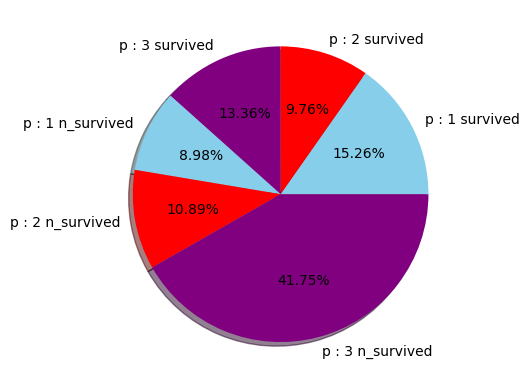

In [ ]:
p_class_sur = pd.DataFrame(df[df["Survived"] == 1]["Pclass"].value_counts())
p_class_not_sur = pd.DataFrame(df[df["Survived"] == 0]["Pclass"].value_counts())
sur_p_class = p_class_sur.merge(p_class_not_sur, on="Pclass", how="outer")
l1 = sur_p_class["count_x"].tolist()
l2 =sur_p_class["count_y"].tolist()
lt = l1 + l2
colors = ["skyblue", "red", "purple", "skyblue", "red", "purple"]
plt.pie(lt, labels=["p : 1 survived", "p : 2 survived", "p : 3 survived", "p : 1 n_survived", "p : 2 n_survived", "p : 3 n_survived"], shadow=True, autopct="%2.2f%%", colors=colors)

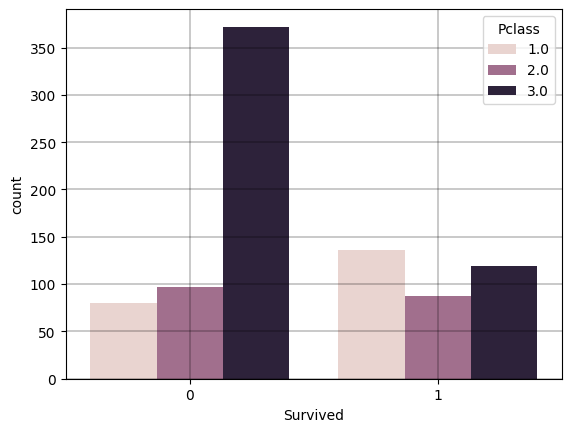

In [ ]:
sns.countplot(data=df, x="Survived", hue="Pclass")
plt.grid(linewidth=0.3, color="black")

C:\Users\USER\AppData\Local\Temp\ipykernel_7544\337711245.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=df, x="Survived", y="Age", palette="Set2", bw=0.2)
C:\Users\USER\AppData\Local\Temp\ipykernel_7544\337711245.py:1: FutureWarning: 

The `bw` parameter is deprecated in favor of `bw_method`/`bw_adjust`.
Setting `bw_method=0.2`, but please see docs for the new parameters
and update your code. This will become an error in seaborn v0.15.0.

  sns.violinplot(data=df, x="Survived", y="Age", palette="Set2", bw=0.2)


<Axes: xlabel='Survived', ylabel='Age'>

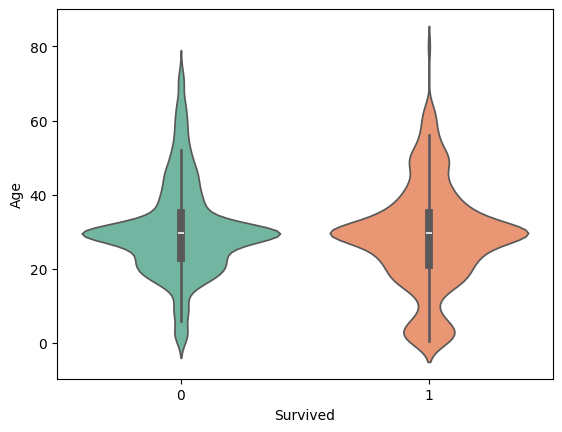

In [ ]:
sns.violinplot(data=df, x="Survived", y="Age", palette="Set2", bw=0.2)

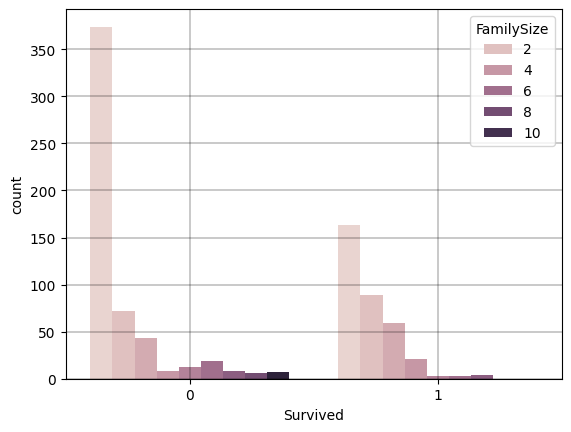

In [ ]:
sns.countplot(data=df, x="Survived", hue="FamilySize")
plt.grid(linewidth=0.3, color="black")

([<matplotlib.axis.XTick at 0x1890765aa70>,
 [Text(1, 0, '1'), Text(2, 0, '2'), Text(3, 0, '3')])

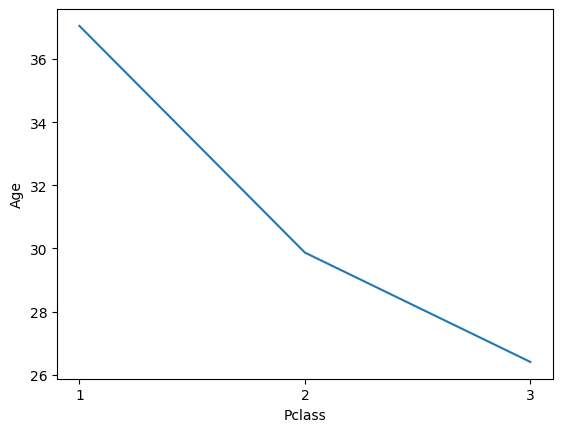

In [ ]:
sex_p_class = df.groupby("Pclass").agg(Age=("Age", "mean")).reset_index()
sns.lineplot(data=sex_p_class, x="Pclass", y="Age")
plt.xticks(np.array([1, 2, 3]))

C:\Users\USER\AppData\Local\Temp\ipykernel_7544\124797468.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="Sex", y="Age", palette="Set2", showmeans=True, meanprops={"marker":"o"})


<Axes: xlabel='Sex', ylabel='Age'>

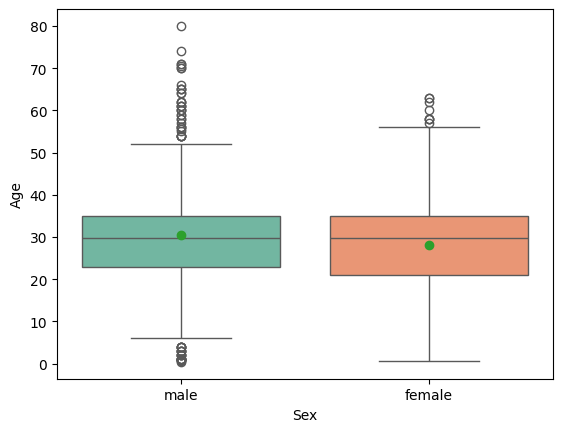

In [ ]:
sns.boxplot(data=df, x="Sex", y="Age", palette="Set2", showmeans=True, meanprops={"marker":"o"})

<Axes: xlabel='Pclass', ylabel='Fare'>

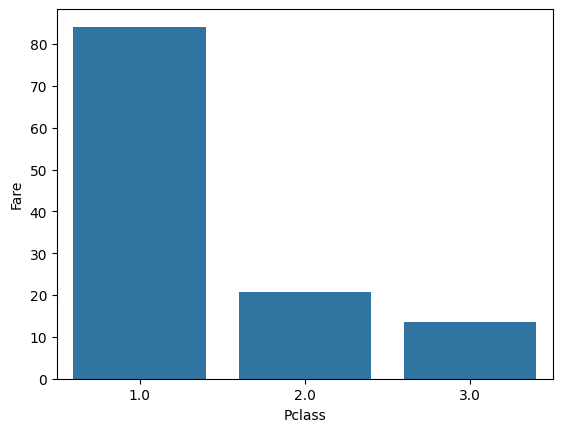

In [ ]:
fare_p_class = df.groupby("Pclass").agg(Fare=("Fare", "mean")).reset_index()
sns.barplot(data=fare_p_class, x="Pclass", y="Fare")

C:\Users\USER\AppData\Local\Temp\ipykernel_7544\1172497080.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="Sex", y="FamilySize", palette="Set2", showmeans=True, meanprops=mean_props)


<Axes: xlabel='Sex', ylabel='FamilySize'>

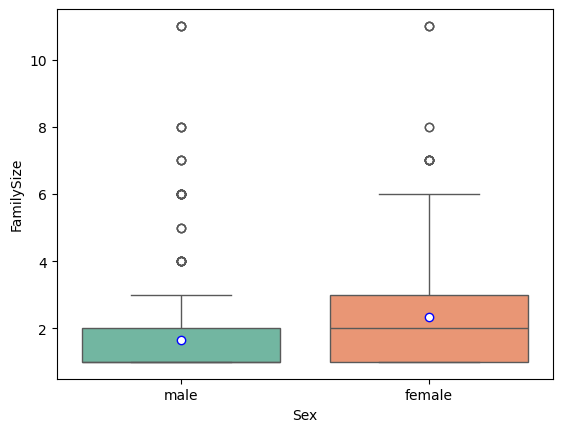

In [ ]:
sx_f_size = df.groupby("Sex").agg(FamilySize=("FamilySize", "mean")).reset_index()
sx_f_size
mean_props = {"marker":"o", "markerfacecolor":"white", "markeredgecolor":"blue"}
sns.boxplot(data=df, x="Sex", y="FamilySize", palette="Set2", showmeans=True, meanprops=mean_props)

<Axes: xlabel='Survived', ylabel='count'>

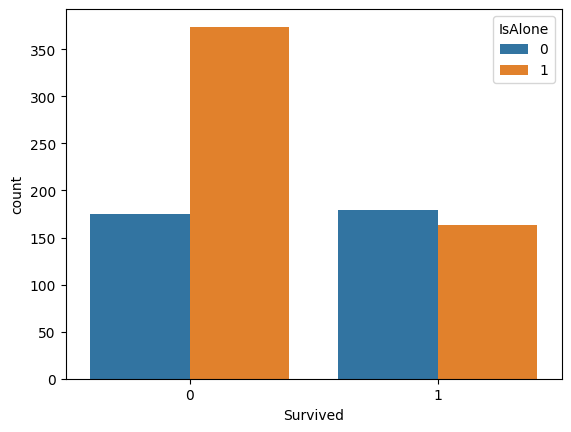

In [ ]:
sns.countplot(data=df, x="Survived", hue="IsAlone")

In [ ]:
input_cols = ["Pclass", "Sex", "Age", "Fare", "IsAlone", "ExtractT"]
target_col = "Survived"
train_df, val_df = train_test_split(df, test_size=0.2, random_state=42)
train_inputs = train_df[input_cols]
val_inputs = val_df[input_cols]
train_target = train_df[[target_col]]
val_target = val_df[[target_col]]
num_columns = train_inputs.select_dtypes(include=np.number).columns.tolist()
cat_columns = train_inputs.select_dtypes("object").columns.tolist()
scale = MinMaxScaler()
scale.fit(df[num_columns])
train_inputs[num_columns] = scale.transform(train_inputs[num_columns])
val_inputs[num_columns] = scale.transform(val_inputs[num_columns])
enc = OneHotEncoder(handle_unknown="ignore")
enc.fit(df[cat_columns])
new_columns = enc.get_feature_names_out(cat_columns).tolist()
train_inputs[new_columns] = enc.transform(train_inputs[cat_columns]).toarray()
val_inputs[new_columns] = enc.transform(val_inputs[cat_columns]).toarray()
x_train = train_inputs[num_columns + new_columns]
x_val = val_inputs[num_columns + new_columns]

C:\Users\USER\AppData\Local\Temp\ipykernel_7544\1337331127.py:12: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  train_inputs[num_columns] = scale.transform(train_inputs[num_columns])
C:\Users\USER\AppData\Local\Temp\ipykernel_7544\1337331127.py:13: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  val_inputs[num_columns] = scale.transform(val_inputs[num_columns])
C:\Users\USER\AppData\Local\Temp\ipykernel_7544\1337331127.py:17: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a Dat

In [ ]:
model = LogisticRegression(random_state=42, n_jobs=-1, penalty="l2", C=20, class_weight="balanced", solver="sag")
model.fit(X=x_train, y=train_target)

C:\Users\USER\AppData\Roaming\Python\Python310\site-packages\sklearn\utils\validation.py:1406: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
C:\Users\USER\AppData\Roaming\Python\Python310\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


,penalty,'l2'
,dual,False
,tol,0.0001
,C,20
,fit_intercept,True
,intercept_scaling,1
,class_weight,'balanced'
,random_state,42
,solver,'sag'
,max_iter,100
,multi_class,'deprecated'


In [ ]:
pred = model.predict(x_train)
model.predict_proba(x_train)
accuracy_score(train_target, pred)

0.776685393258427

In [ ]:
model.score(x_val, val_target)

0.7988826815642458

C:\Users\USER\AppData\Roaming\Python\Python310\site-packages\sklearn\utils\validation.py:1406: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
C:\Users\USER\AppData\Roaming\Python\Python310\site-packages\sklearn\utils\validation.py:1406: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
C:\Users\USER\AppData\Roaming\Python\Python310\site-packages\sklearn\utils\validation.py:1406: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
C:\Users\USER\AppData\Roaming\Python\Python310\site-packages\sklearn\utils\validation.py:1406: DataConversionWarning: A column-vector y was passed w

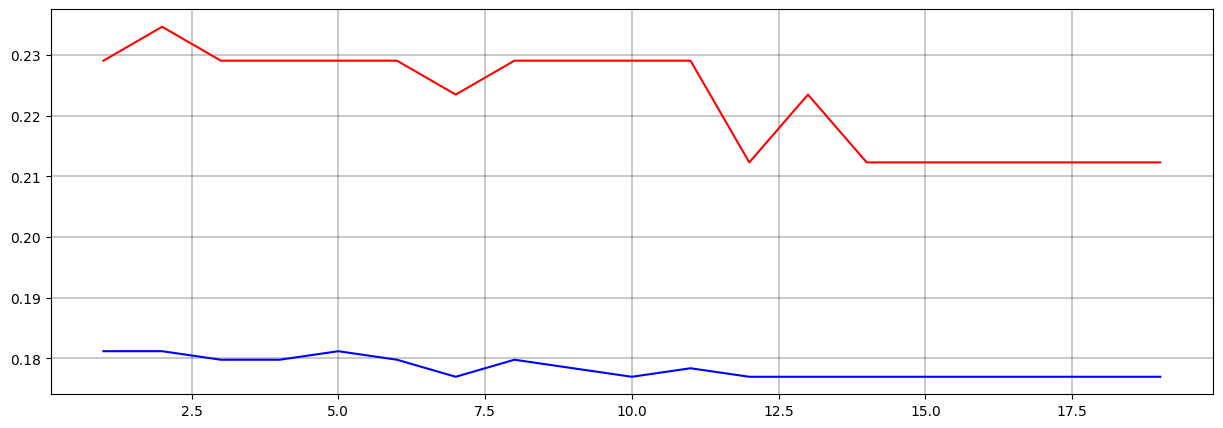

In [ ]:
def best_C(c):
    m = LogisticRegression(random_state=42, n_jobs=-1, penalty="l2", C=c)
    m.fit(X=x_train, y=train_target)
    train_error = 1 - m.score(x_train, train_target)
    val_error = 1 - m.score(x_val, val_target)
    return {"c":c, "train_error":train_error, "val_error":val_error}
c_df = pd.DataFrame([best_C(c) for c in range(1, 20)])
plt.figure(figsize=(15, 5))
plt.plot(c_df["c"], c_df["train_error"], color="blue")
plt.plot(c_df["c"], c_df["val_error"], color="red")
plt.grid(linewidth=0.3, color="black")

C:\Users\USER\AppData\Roaming\Python\Python310\site-packages\sklearn\utils\validation.py:1406: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
C:\Users\USER\AppData\Roaming\Python\Python310\site-packages\sklearn\utils\validation.py:1406: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
C:\Users\USER\AppData\Roaming\Python\Python310\site-packages\sklearn\linear_model\_logistic.py:1305: UserWarning: 'n_jobs' > 1 does not have any effect when 'solver' is set to 'liblinear'. Got 'n_jobs' = 12.
  warnings.warn(
C:\Users\USER\AppData\Roaming\Python\Python310\site-packages\sklearn\utils\validation.py:1406: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y t

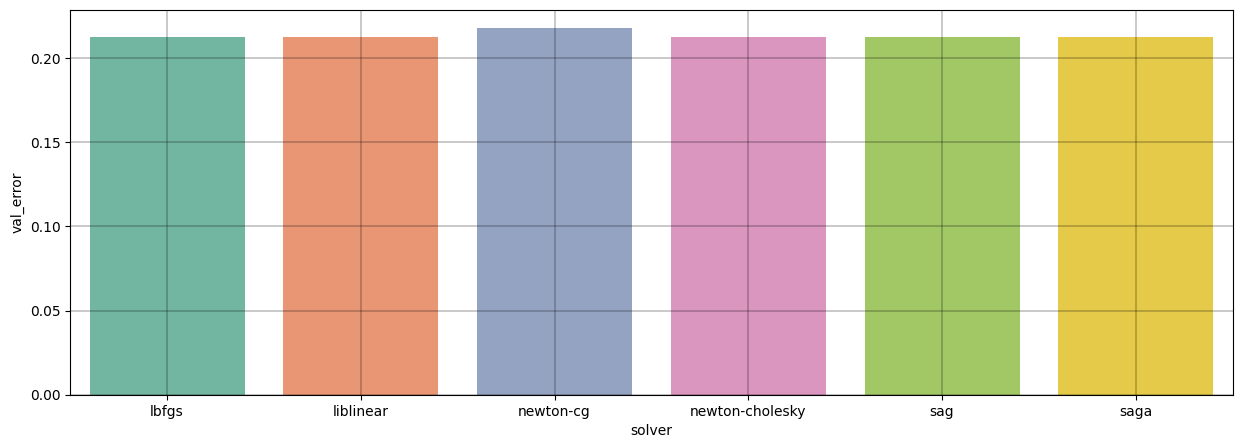

In [ ]:
l = ['lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga']
def best_s(s):
    m = LogisticRegression(random_state=42, n_jobs=-1, penalty="l2", C=20, solver=s)
    m.fit(X=x_train, y=train_target)
    val_error = 1 - m.score(x_val, val_target)
    return {"solver":s, "val_error":val_error}
s_df = pd.DataFrame([best_s(s) for s in l])
plt.figure(figsize=(15, 5))
sns.barplot(x=s_df["solver"], y=s_df["val_error"], palette="Set2")
plt.grid(linewidth=0.3, color="black")

<Axes: >

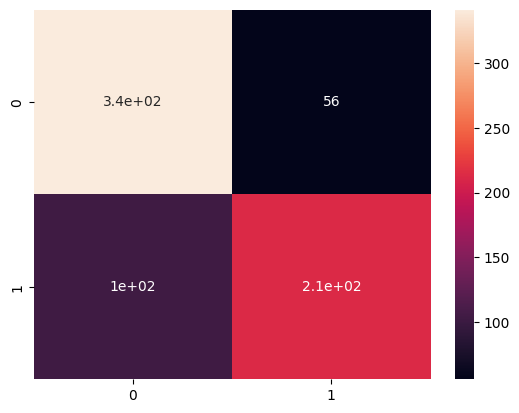

In [ ]:
sns.heatmap(confusion_matrix(pred, train_target), annot=True)

In [ ]:
model1 = RandomForestClassifier(random_state=42, n_jobs=-1, max_depth=9, n_estimators=121, max_features="sqrt", min_samples_split=2, criterion="log_loss", class_weight="balanced")
model1.fit(X=x_train, y=train_target)

C:\Users\USER\AppData\Roaming\Python\Python310\site-packages\sklearn\base.py:1365: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)


,n_estimators,121
,criterion,'log_loss'
,max_depth,9
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [ ]:
model1.predict(x_train)
model1.predict_proba(x_train)
model1.score(x_train, train_target)

0.925561797752809

In [ ]:
model1.score(x_val, val_target)

0.8491620111731844

C:\Users\USER\AppData\Roaming\Python\Python310\site-packages\sklearn\base.py:1365: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)
C:\Users\USER\AppData\Roaming\Python\Python310\site-packages\sklearn\base.py:1365: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)
C:\Users\USER\AppData\Roaming\Python\Python310\site-packages\sklearn\base.py:1365: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)
C:\Users\USER\AppData\Roaming\Python\Python310\site-packages\sklearn\base.py:1365: DataConversionWarning: A column-vector y was passed when a 

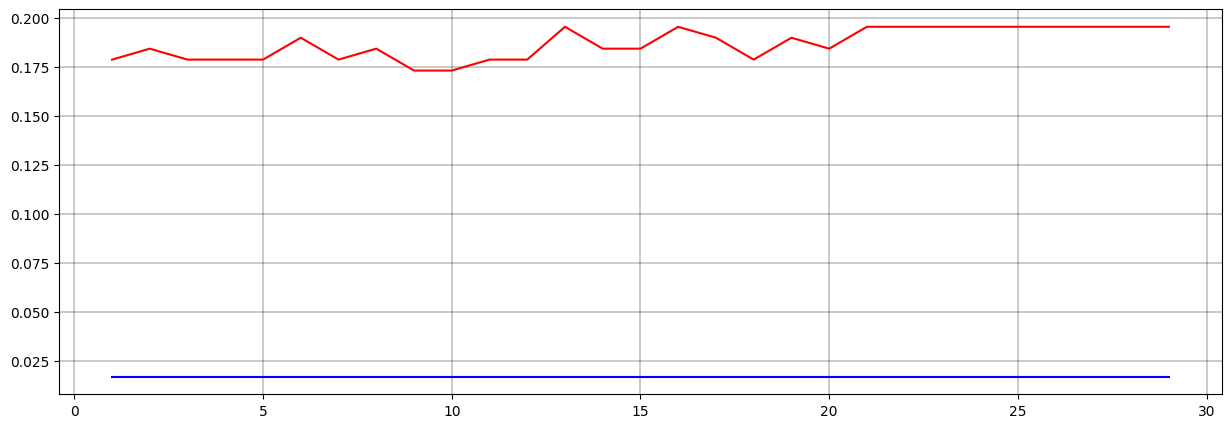

In [ ]:
def best_max_depth(md):
    m1 = RandomForestClassifier(random_state=42, n_jobs=-1, max_features=md)
    m1.fit(X=x_train, y=train_target)
    train_error = 1 - m1.score(x_train, train_target)
    val_error = 1 - m1.score(x_val, val_target)
    return {"max_depths":md, "train_error":train_error, "val_error":val_error}
depths_df = pd.DataFrame([best_max_depth(md) for md in range(1, 30)])
plt.figure(figsize=(15, 5))
plt.plot(depths_df["max_depths"], depths_df["train_error"], color="blue")
plt.plot(depths_df["max_depths"], depths_df["val_error"], color="red")
plt.grid(linewidth=0.3, color="black")

C:\Users\USER\AppData\Roaming\Python\Python310\site-packages\sklearn\base.py:1365: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)
C:\Users\USER\AppData\Roaming\Python\Python310\site-packages\sklearn\base.py:1365: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)
C:\Users\USER\AppData\Roaming\Python\Python310\site-packages\sklearn\base.py:1365: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)
C:\Users\USER\AppData\Roaming\Python\Python310\site-packages\sklearn\base.py:1365: DataConversionWarning: A column-vector y was passed when a 

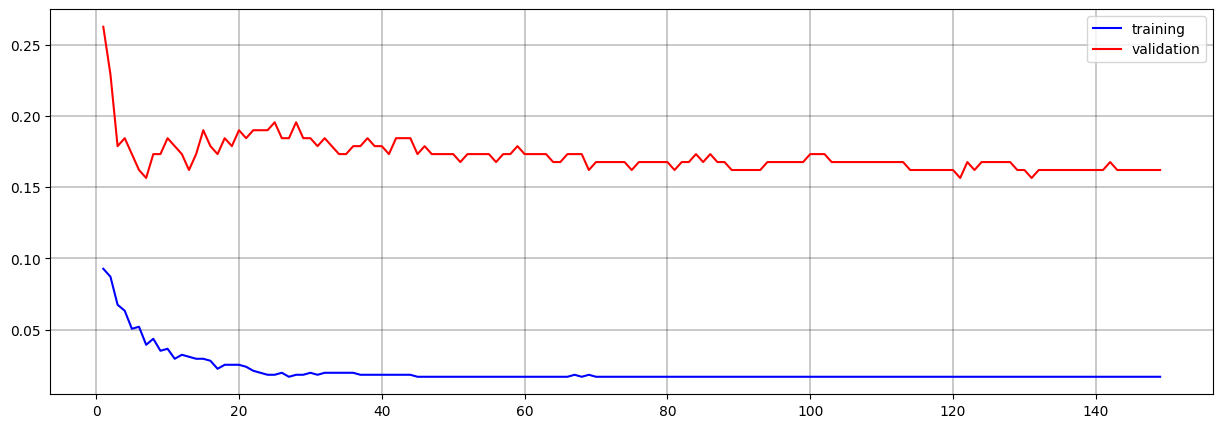

In [ ]:
def best_ne_depth(ne):
    m1 = RandomForestClassifier(random_state=42, n_jobs=-1, max_features=9, n_estimators=ne)
    m1.fit(X=x_train, y=train_target)
    train_error = 1 - m1.score(x_train, train_target)
    val_error = 1 - m1.score(x_val, val_target)
    return {"n_estimators":ne, "train_error":train_error, "val_error":val_error}
n_estimators_df = pd.DataFrame([best_ne_depth(ne) for ne in range(1, 150)])
n_estimators_df[n_estimators_df["train_error"] == n_estimators_df["train_error"].describe().loc["min"]][["n_estimators", "val_error"]]
plt.figure(figsize=(15, 5))
plt.plot(n_estimators_df["n_estimators"], n_estimators_df["train_error"], color="blue")
plt.plot(n_estimators_df["n_estimators"], n_estimators_df["val_error"], color="red")
plt.grid(linewidth=0.3, color="black")
plt.legend(["training", "validation"])

In [ ]:
n_estimators_df[n_estimators_df["train_error"] == n_estimators_df["train_error"].describe().loc["min"]][["n_estimators", "val_error"]].sort_values("val_error", ascending=True)

,n_estimators,val_error
130,131,0.156425
120,121,0.156425
74,75,0.162011
91,92,0.162011
92,93,0.162011
...,...,...
101,102,0.173184
85,86,0.173184
45,46,0.178771
58,59,0.178771


C:\Users\USER\AppData\Roaming\Python\Python310\site-packages\sklearn\base.py:1365: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)
C:\Users\USER\AppData\Roaming\Python\Python310\site-packages\sklearn\base.py:1365: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)
C:\Users\USER\AppData\Roaming\Python\Python310\site-packages\sklearn\base.py:1365: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)
C:\Users\USER\AppData\Roaming\Python\Python310\site-packages\sklearn\base.py:1365: DataConversionWarning: A column-vector y was passed when a 

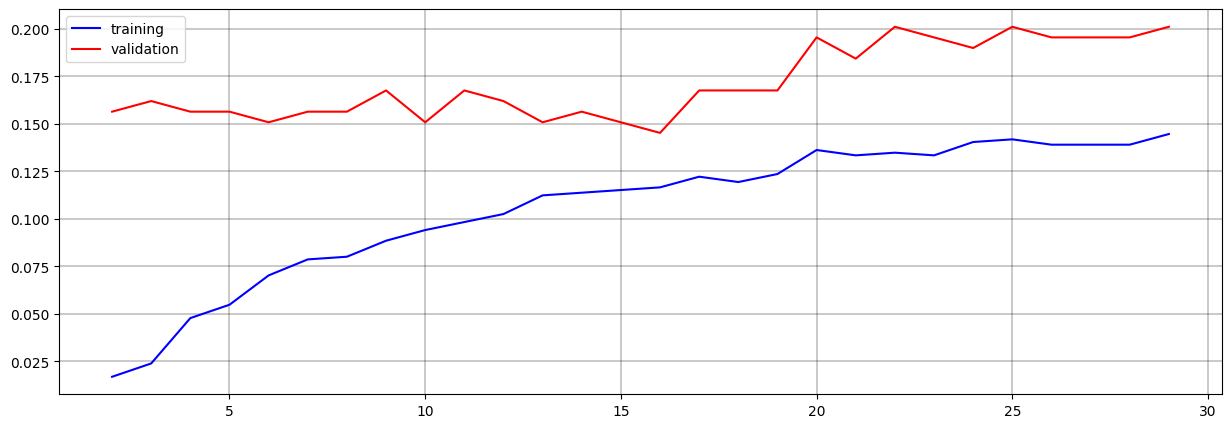

In [ ]:
def best_min_samples_split(mss):
    m1 = RandomForestClassifier(random_state=42, n_jobs=-1, max_features=9, n_estimators=121, min_samples_split=mss)
    m1.fit(X=x_train, y=train_target)
    train_error = 1 - m1.score(x_train, train_target)
    val_error = 1 - m1.score(x_val, val_target)
    return {"min_samples_split":mss, "train_error":train_error, "val_error":val_error}
min_samples_split_df = pd.DataFrame([best_min_samples_split(mss) for mss in range(2, 30)])
plt.figure(figsize=(15, 5))
plt.plot(min_samples_split_df["min_samples_split"], min_samples_split_df["train_error"], color="blue")
plt.plot(min_samples_split_df["min_samples_split"], min_samples_split_df["val_error"], color="red")
plt.grid(linewidth=0.3, color="black")
plt.legend(["training", "validation"])

In [ ]:
min_samples_split_df[min_samples_split_df["train_error"] == min_samples_split_df["train_error"].describe().loc["min"]][["min_samples_split", "val_error"]]

,min_samples_split,val_error
0,2,0.156425


C:\Users\USER\AppData\Roaming\Python\Python310\site-packages\sklearn\base.py:1365: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)
C:\Users\USER\AppData\Roaming\Python\Python310\site-packages\sklearn\base.py:1365: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)
C:\Users\USER\AppData\Roaming\Python\Python310\site-packages\sklearn\base.py:1365: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)
C:\Users\USER\AppData\Roaming\Python\Python310\site-packages\sklearn\base.py:1365: DataConversionWarning: A column-vector y was passed when a 

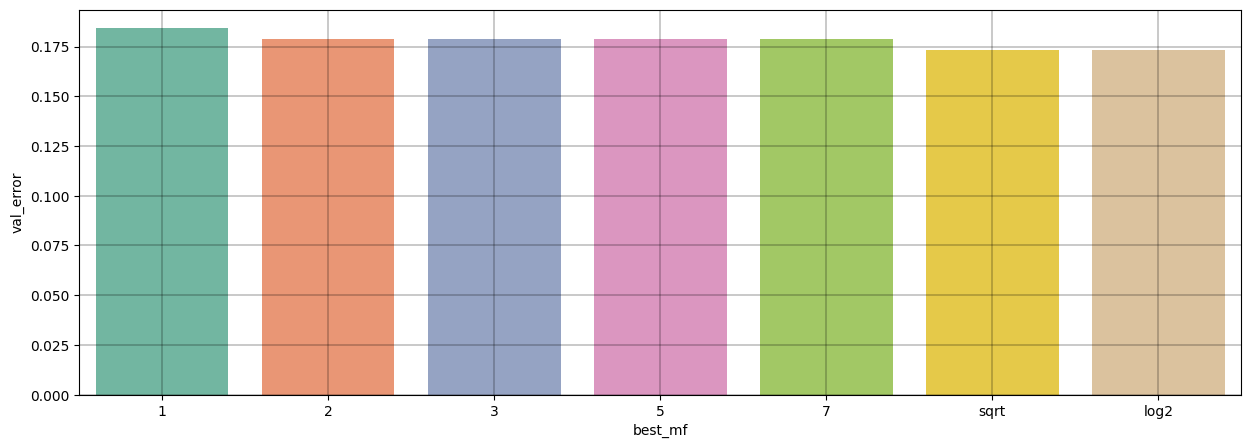

In [ ]:
l1 = [1, 2, 3, 5, 7, "sqrt", "log2"]
def best_mf(mf):
    m3 = RandomForestClassifier(random_state=42, n_jobs=-1, n_estimators=121, max_features=mf)
    m3.fit(X=x_train, y=train_target)
    val_error = 1 - m3.score(x_val, val_target)
    return {"best_mf":mf, "val_error":val_error}
mf_df = pd.DataFrame([best_mf(mf) for mf in l1])
plt.figure(figsize=(15, 5))
sns.barplot(x=mf_df["best_mf"], y=mf_df["val_error"], palette="Set2")
plt.grid(linewidth=0.3, color="black")

<Axes: >

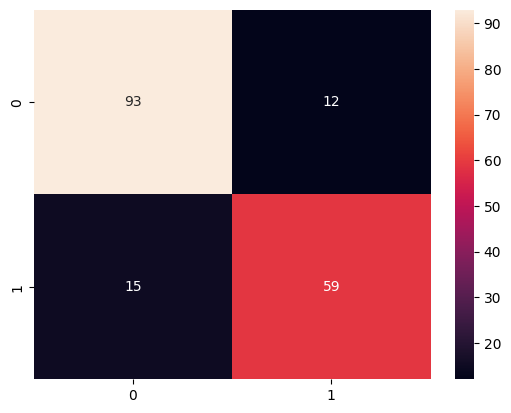

In [ ]:
sns.heatmap(confusion_matrix(val_target, model1.predict(x_val)), annot=True)